In [1]:
from backend.utils.gmsh_function import *
from backend.utils.file_path import *
from backend.src.radiation_algorithm.radiation_algorithm import *

from plate_gmsh import *

from backend.cma.cma_algorithm import cma_algorithm
from backend.cma.cma_frequency_sweep import cma_frequency_sweep
from backend.cma.modal_current import ModalCurrent
from backend.cma.modal_farfield import compute_modal_farfield
from backend.cma.modal_visualizer import ModalVisualizer
from backend.cma.modal_significance import modal_significance

In [2]:
name = "plate"
path = setup_save_file_paths(name)

In [3]:
cm = 1e-2 # 1 cm
mm = 1e-3 # 1 mm

Long = 80 * mm
larg = 40 * mm

print("plate size: long =", Long, "width =", larg)

initial_mesh_size = 5 * mm

plate size: long = 0.08 width = 0.04


In [ ]:
# Coding the Nice CubeSat geometry
gmsh.initialize()

gmsh.model.add("CubeSat")

setup_performance_config()

plate = construct_plate_geometry(Long, larg)

generate_and_save_mesh(path, initial_mesh_size)

# gmsh.fltk.run()

gmsh.finalize()

[PERFORMANCE] Gmsh configured to utilize 16 threads.
Geometry file saved in data/gmsh_files/plate.brep successfully
--- Starting Mesh Optimization (Dim: 2) ---
--- Optimization Complete ---
Mesh file saved in data/gmsh_files/plate.msh successfully


In [5]:
feed_point = np.array([Long/2, larg/2, 0])  # Feed point coordinates (x, y, z)

light_speed = 3e8
frequency = 1e9

wavelength = light_speed / frequency
print(f"wavelength = {wavelength} Meter")

wavelength = 0.3 Meter


_ = radiation_algorithm(path, frequency, feed_point, 
                        excitation_unit_vector='x',
                        gap_width=2*initial_mesh_size,
                        show=True, save_image=False)

## Characteristic Mode Analysis (CMA)

Both `cma_frequency_sweep()` and `cma_algorithm()` are self-sufficient: they re-derive the
mesh from `path.msh` and (re)compute the impedance matrix themselves, rather than trusting
whatever `path.mat_mesh2`/`path.mat_impedance` last happened to contain. The
`radiation_algorithm()` call above only needs to have run once so `frequency` is defined.

1. Eigenvalues lambda_n(f) over a frequency range (`cma_frequency_sweep`), plotted for the
   first 4 modes.
2. Modal Significance MS_n(f) = 1/sqrt(1 + lambda_n^2) for the same 4 modes.
3. Characteristic currents and far-field patterns of the first 4 modes, at the plate's
   design frequency (`frequency` = 1 GHz).

In [6]:
# 1. Eigenvalues over a frequency range
n_modes_cma = 4

freq_start_cma = 0.3e9
freq_stop_cma = 2.0e9

sweep_data = cma_frequency_sweep(path, freq_start_cma, freq_stop_cma, n_points=11, n_modes=n_modes_cma)

Mesh ready: 181 points, 312 triangles, 444 edges -- regenerated from data/gmsh_files/plate.msh

Assembling Z(f) for 11 frequencies (444x444 edges) on GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) -- geometry reused across the whole sweep...
[calculate_z_matrice_sweep] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (444x444 edges, 11 frequencies).
Z(f) assembly done in 9.5 s (0.865 s/frequency amortised)

Step 1/11 |   300.00 MHz | lambda: -234.230, -674.512, 1078.641, -165553.180
Step 2/11 |   470.00 MHz | lambda: -57.469, -175.003, 287.776, -17481.231
Step 3/11 |   640.00 MHz | lambda: -20.800, -68.959, 118.252, -3713.931
Step 4/11 |   810.00 MHz | lambda: -9.206, -34.522, 60.791, -1135.200
Step 5/11 |   980.00 MHz | lambda: -4.430, -19.655, 36.072, -433.535
Step 6/11 |  1150.00 MHz | lambda: -2.159, -12.164, 23.676, -192.318
Step 7/11 |  1320.00 MHz | lambda: -1.000, -8.158, 16.679, -94.936
Step 8/11 |  1490.00 MHz | lambda: -0.368, -5.726, 12.385, -50.

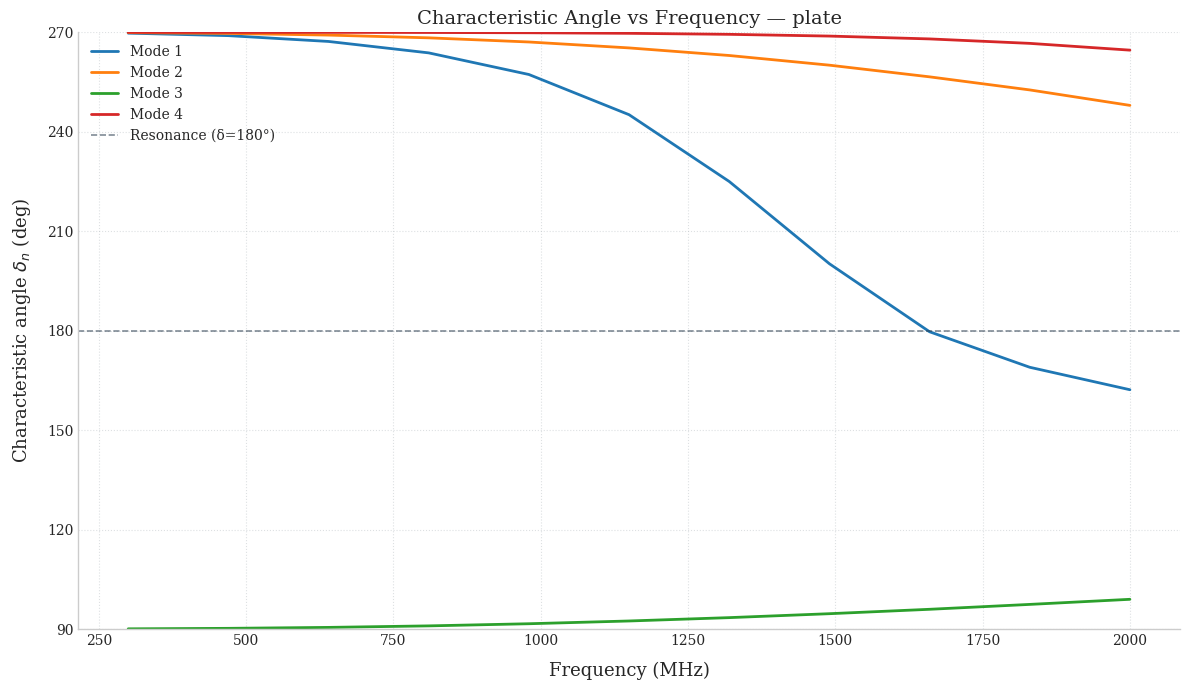

In [7]:
# 2. Characteristic angle delta_n = 180 - atan(lambda_n)
ModalVisualizer.plot_characteristic_angle_vs_frequency(sweep_data, n_modes_to_plot=n_modes_cma, antenna_name=path.name)

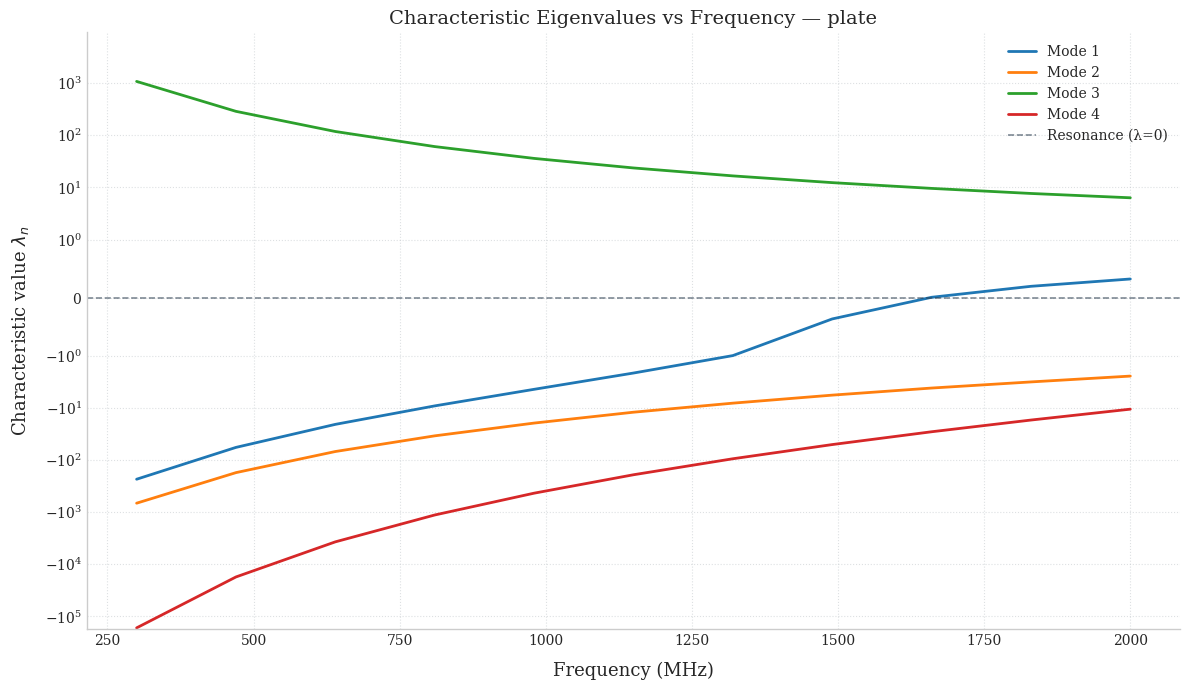

In [8]:
# 3. Eigenvalue curve for the first 4 modes
ModalVisualizer.plot_eigenvalues_vs_frequency(sweep_data, n_modes_to_plot=n_modes_cma, antenna_name=path.name)

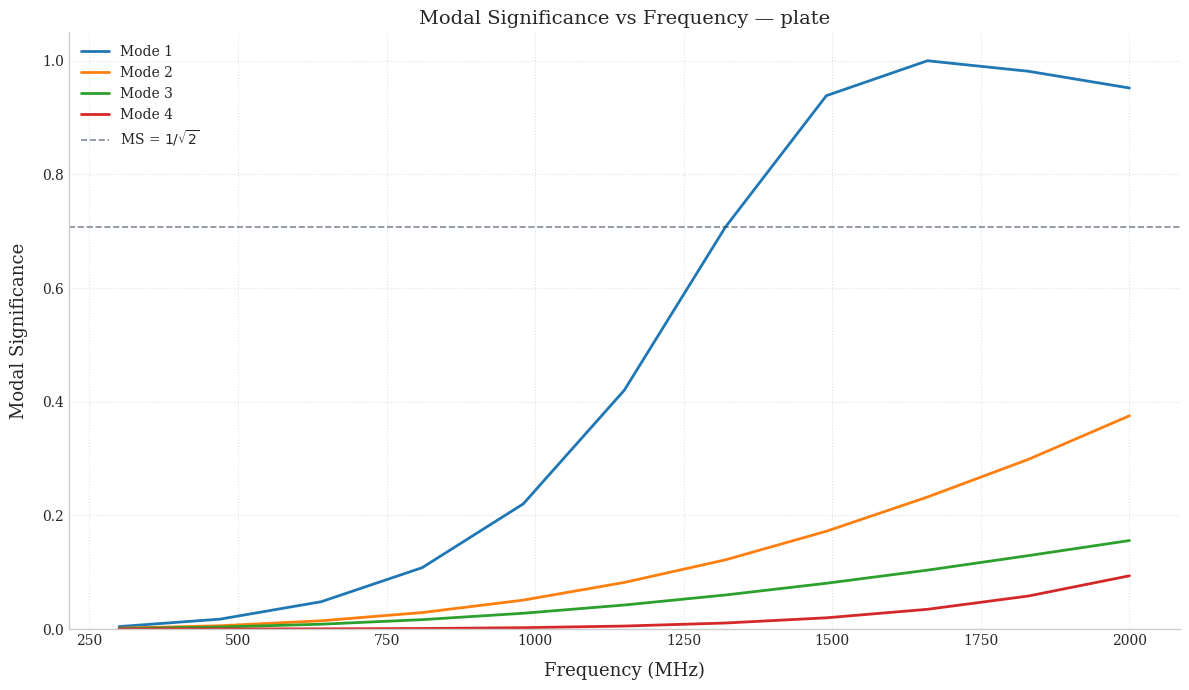

In [9]:
# 3. Modal Significance for the first 4 modes
ModalVisualizer.plot_modal_significance(sweep_data, n_modes_to_plot=n_modes_cma, antenna_name=path.name)

In [10]:
# 4. Characteristic currents of the first 4 modes, at the plate's design frequency
modal_data = cma_algorithm(path, frequency=frequency, n_modes=n_modes_cma, show=True)

[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (444x444 edges).
CMA: 4 modes computed at f = 1.0000 GHz
  λ range: [-391.3786, 34.1591]


In [11]:
# 5. Far-field pattern of the first 4 modes, at the same design frequency
_, triangles, edges, _vecteurs_rho = DataManager_rwg2.load_data(path.mat_mesh2)
freq_cma, _omega, _mu, _epsilon, light_speed_c, eta, _Z = DataManager_rwg3.load_data(path.mat_impedance)

for n in range(n_modes_cma):
    J_n = modal_data.eigenvectors[:, n]
    sphere_points, sphere_triangles, gain_db, directivity_max = compute_modal_farfield(
        triangles, edges, J_n, freq_cma, light_speed_c, eta)
    print(f"Mode {n + 1} (lambda = {modal_data.eigenvalues[n]:.4f}): "
          f"peak directivity = {10 * np.log10(directivity_max):.2f} dBi")
    fig = ModalVisualizer.plot_mode_farfield(sphere_points, sphere_triangles, gain_db,
                                              mode_index=n, eigenvalue=modal_data.eigenvalues[n])
    fig.show()

Hollow sphere loaded: 5150 points, 10296 triangles.
Mode 1 (lambda = -4.0820): peak directivity = 2.05 dBi


Hollow sphere loaded: 5150 points, 10296 triangles.
Mode 2 (lambda = -18.5088): peak directivity = 2.48 dBi


Hollow sphere loaded: 5150 points, 10296 triangles.
Mode 3 (lambda = 34.1591): peak directivity = 2.42 dBi


Hollow sphere loaded: 5150 points, 10296 triangles.
Mode 4 (lambda = -391.3786): peak directivity = 4.10 dBi
